<a href="https://colab.research.google.com/github/gizemnurbektas/opencv-license-plate-recognition/blob/main/automatic_license_plate_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install easyocr


In [2]:
import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt
import re

from google.colab import files


Saving 06  ABV784.jpg to 06  ABV784.jpg


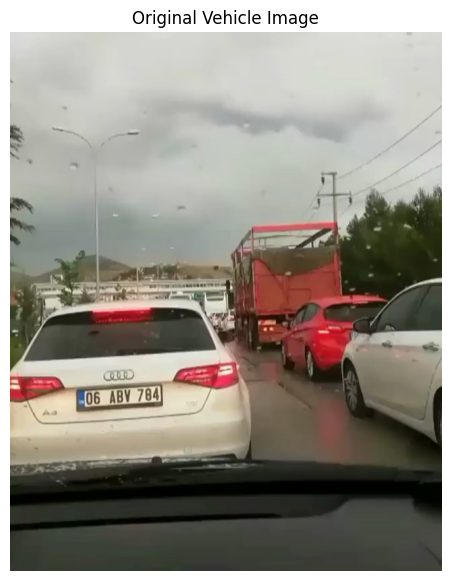

In [3]:
uploaded = files.upload()

filename = next(iter(uploaded))

img = cv2.imread(filename)

if img is None:
    raise ValueError("Image could not be loaded!")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(img_rgb)
plt.title("Original Vehicle Image")
plt.axis("off")
plt.show()


In [4]:
import torch

reader = easyocr.Reader(
    ['en'],
    gpu=torch.cuda.is_available()
)


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

In [5]:
results = reader.readtext(
    img_rgb,
    allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
)

for bbox, text, confidence in results:
    print("Detected text:", text)
    print("Confidence:", round(confidence, 3))
    print("----------------------")


Detected text: 06ZEL781
Confidence: 0.148
----------------------


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


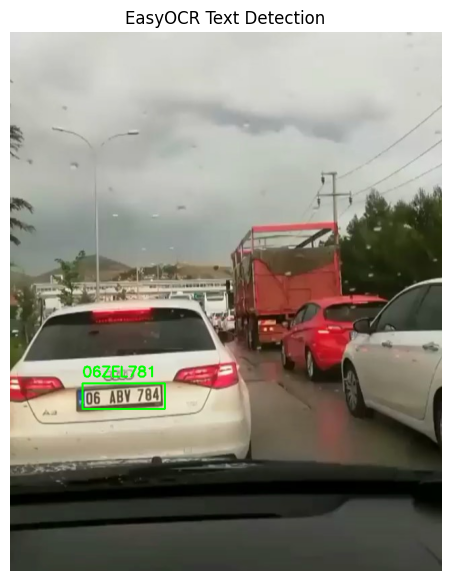

In [6]:

result_img = img_rgb.copy()

for bbox, text, confidence in results:

    points = np.array(bbox, dtype=np.int32)

    cv2.polylines(
        result_img,
        [points],
        True,
        (0, 255, 0),
        2
    )

    x, y = points[0]

    cv2.putText(
        result_img,
        text,
        (int(x), max(20, int(y) - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12, 7))
plt.imshow(result_img)
plt.title("EasyOCR Text Detection")
plt.axis("off")
plt.show()


In [7]:

def is_turkish_plate(text):

    text = re.sub(r'[^A-Z0-9]', '', text.upper())

    pattern = r'(0[1-9]|[1-7][0-9]|8[01])[A-Z]{1,3}[0-9]{2,5}'

    return re.fullmatch(pattern, text) is not None


detected_plates = []

for bbox, text, confidence in results:

    cleaned_text = re.sub(
        r'[^A-Z0-9]', '', text.upper()
    )

    if is_turkish_plate(cleaned_text):
        detected_plates.append(
            (bbox, cleaned_text, confidence)
        )

print("Detected plates:")

for plate in detected_plates:
    print(plate[1])


Detected plates:
06ZEL781


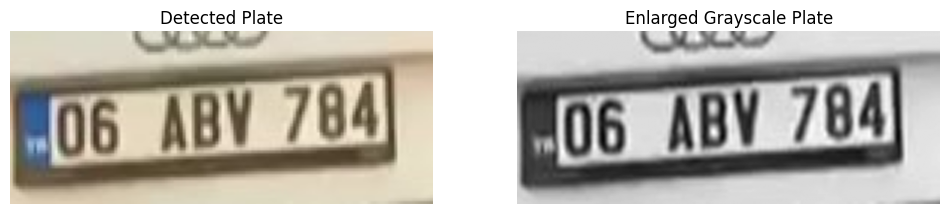

Original recognition: 06ZEL781
Second OCR attempt: ['3', '06ZBV7808']


In [8]:

if detected_plates:

    bbox, plate_text, confidence = max(
        detected_plates,
        key=lambda item: item[2]
    )

    points = np.array(bbox, dtype=np.int32)

    x1 = max(0, points[:, 0].min() - 10)
    y1 = max(0, points[:, 1].min() - 10)
    x2 = min(img.shape[1], points[:, 0].max() + 10)
    y2 = min(img.shape[0], points[:, 1].max() + 10)

    plate_crop = img_rgb[y1:y2, x1:x2]

    enlarged = cv2.resize(
        plate_crop,
        None,
        fx=3,
        fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    gray_plate = cv2.cvtColor(
        enlarged,
        cv2.COLOR_RGB2GRAY
    )

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(plate_crop)
    plt.title("Detected Plate")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(gray_plate, cmap="gray")
    plt.title("Enlarged Grayscale Plate")
    plt.axis("off")

    plt.show()

    refined_results = reader.readtext(
        gray_plate,
        detail=0,
        allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
    )

    print("Original recognition:", plate_text)
    print("Second OCR attempt:", refined_results)

else:
    print("No complete Turkish plate detected.")
    print("Try a clearer image or crop the plate manually.")


In [9]:

# Resize image
scale = 4

plate_large = cv2.resize(
    plate_crop,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_CUBIC
)

# Convert to grayscale
gray = cv2.cvtColor(
    plate_large,
    cv2.COLOR_RGB2GRAY
)

# Apply CLAHE contrast enhancement
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)

# Reduce noise
denoised = cv2.bilateralFilter(
    enhanced,
    7,
    50,
    50
)

# Sharpen image
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(
    denoised,
    -1,
    kernel
)

# Otsu thresholding
_, binary = cv2.threshold(
    sharpened,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)


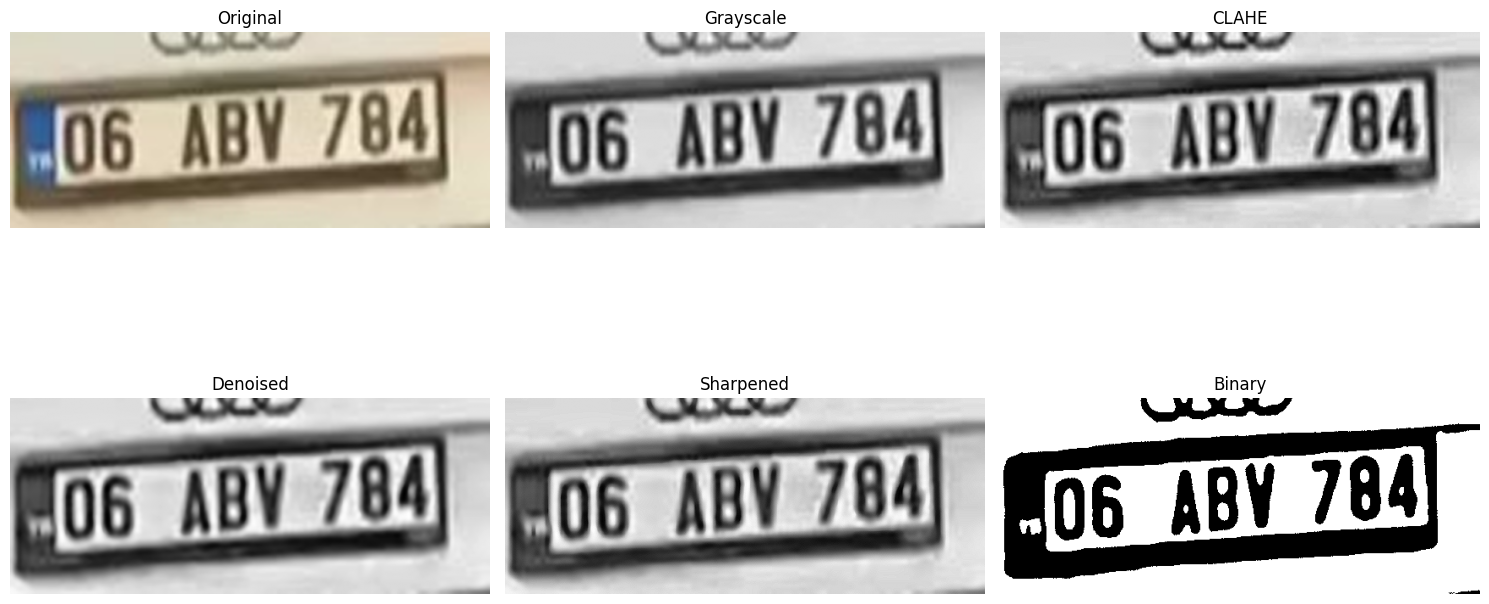

In [10]:

images = {
    "Original": plate_large,
    "Grayscale": gray,
    "CLAHE": enhanced,
    "Denoised": denoised,
    "Sharpened": sharpened,
    "Binary": binary
}

plt.figure(figsize=(15, 9))

for i, (name, image) in enumerate(images.items()):

    plt.subplot(2, 3, i + 1)

    if len(image.shape) == 3:
        plt.imshow(image)
    else:
        plt.imshow(image, cmap="gray")

    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [11]:

ocr_results = {}

for name, image in images.items():

    results = reader.readtext(
        image,
        detail=1,
        paragraph=False,
        allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789",
        decoder="beamsearch",
        beamWidth=10
    )

    ocr_results[name] = results

    print(f"\n{name}")

    if not results:
        print("No text detected")
        continue

    for bbox, text, confidence in results:
        print(
            f"Text: {text} | "
            f"Confidence: {confidence:.3f}"
        )



Original
Text:  | Confidence: 0.015
Text: 006 | Confidence: 0.726
Text: 784 | Confidence: 0.391
Text: ABV | Confidence: 0.160

Grayscale
Text:  | Confidence: 0.012
Text: 006 | Confidence: 0.661
Text: 704 | Confidence: 0.842
Text: ABV | Confidence: 0.182

CLAHE
Text:  | Confidence: 0.000
Text: 006 | Confidence: 0.800
Text: 700 | Confidence: 0.326
Text: ABV | Confidence: 0.395

Denoised
Text:  | Confidence: 0.008
Text: 006 | Confidence: 0.895
Text: 780 | Confidence: 0.340
Text: ABV | Confidence: 0.227

Sharpened
Text: O | Confidence: 0.020
Text: 06 | Confidence: 0.912
Text: 704 | Confidence: 0.814
Text: ABM | Confidence: 0.406

Binary
Text: OOS | Confidence: 0.018
Text: 06LV78 | Confidence: 0.340


In [12]:

import re

def clean_plate(text):
    return re.sub(
        r"[^A-Z0-9]",
        "",
        text.upper()
    )

def valid_plate(text):

    pattern = (
        r"(0[1-9]|[1-7][0-9]|8[01])"
        r"[A-Z]{1,3}"
        r"[0-9]{2,5}"
    )

    return re.fullmatch(pattern, text) is not None


candidates = []

for method, results in ocr_results.items():

    combined = "".join(
        clean_plate(text)
        for bbox, text, confidence in
        sorted(results, key=lambda r: min(p[0] for p in r[0]))
    )

    if valid_plate(combined):
        candidates.append((method, combined))

    print(
        method,
        "->",
        combined,
        "| Valid:",
        valid_plate(combined)
    )

print("\nValid candidates:", candidates)


Original -> 006ABV784 | Valid: False
Grayscale -> 006ABV704 | Valid: False
CLAHE -> 006ABV700 | Valid: False
Denoised -> 006ABV780 | Valid: False
Sharpened -> 06OABM704 | Valid: False
Binary -> 06LV78OOS | Valid: False

Valid candidates: []


In [13]:

def clean_plate(text):

    text = re.sub(
        r"[^A-Z0-9]",
        "",
        text.upper()
    )

    # Remove extra leading zeros
    while text.startswith("00"):
        text = text[1:]

    return text



In [14]:
candidates = []

for method, results in ocr_results.items():

    combined = "".join(
        re.sub(r"[^A-Z0-9]", "", text.upper())
        for bbox, text, confidence in
        sorted(results, key=lambda r: min(p[0] for p in r[0]))
    )

    cleaned = clean_plate(combined)

    is_valid = valid_plate(cleaned)

    print(
        f"{method}: {cleaned} | Valid: {is_valid}"
    )

    if is_valid:
        candidates.append((method, cleaned))

print("\nValid candidates:", candidates)


Original: 06ABV784 | Valid: True
Grayscale: 06ABV704 | Valid: True
CLAHE: 06ABV700 | Valid: True
Denoised: 06ABV780 | Valid: True
Sharpened: 06OABM704 | Valid: False
Binary: 06LV78OOS | Valid: False

Valid candidates: [('Original', '06ABV784'), ('Grayscale', '06ABV704'), ('CLAHE', '06ABV700'), ('Denoised', '06ABV780')]


Recognized Plate: 06ABV784


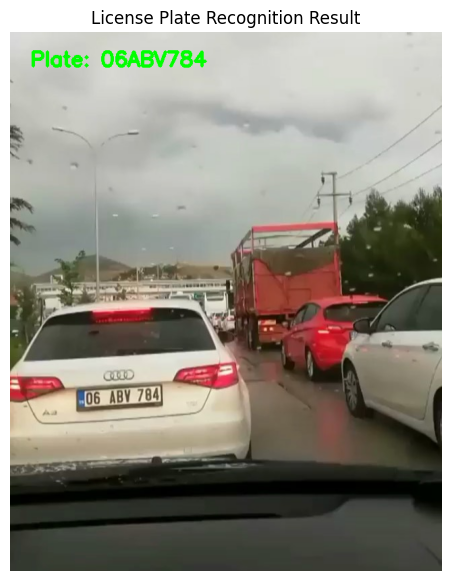

In [15]:
original_results = ocr_results["Original"]

raw_text = "".join(
    text
    for bbox, text, confidence in
    sorted(original_results, key=lambda r: min(p[0] for p in r[0]))
)

plate_number = clean_plate(raw_text)

print("Recognized Plate:", plate_number)

final_image = img_rgb.copy()

cv2.putText(
    final_image,
    f"Plate: {plate_number}",
    (30, 50),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 255, 0),
    3
)

plt.figure(figsize=(12, 7))
plt.imshow(final_image)
plt.title("License Plate Recognition Result")
plt.axis("off")
plt.show()


In [16]:
import os, zipfile, cv2
from google.colab import files

os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Keep one attributed example image and the key notebook outputs.
cv2.imwrite("images/sample_vehicle.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite("results/initial_easyocr_result.png", cv2.cvtColor(result_img, cv2.COLOR_RGB2BGR))
cv2.imwrite("results/detected_plate_crop.png", cv2.cvtColor(plate_crop, cv2.COLOR_RGB2BGR))
cv2.imwrite("results/final_recognition.png", cv2.cvtColor(final_image, cv2.COLOR_RGB2BGR))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, image) in zip(axes.flat, images.items()):
    if len(image.shape) == 3:
        ax.imshow(image)
    else:
        ax.imshow(image, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
fig.savefig("results/preprocessing_comparison.png", dpi=160, bbox_inches="tight")
plt.close(fig)

with zipfile.ZipFile("alpr_project_assets.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for folder in ("images", "results"):
        for name in os.listdir(folder):
            archive.write(os.path.join(folder, name), os.path.join(folder, name))

print("Saved input, initial OCR result, crop, preprocessing comparison, and final result.")
files.download("alpr_project_assets.zip")

Saved input, initial OCR result, crop, preprocessing comparison, and final result.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>